In [1]:
from __future__ import division 
import math as mth
import numpy as np
import matplotlib.pylab as plt 
from sympy import *
import pandas as pd
import os, subprocess
from sklearn.linear_model import LinearRegression, RANSACRegressor, Lasso
from sklearn.linear_model.ransac import _dynamic_max_trials

In [2]:
pwd


'C:\\Users\\gd\\Desktop\\DIPLOMATIKI\\python askiseis diplwmatikis\\projects\\project_4_4G06615'

In [3]:
# y=ax+b briskw a,b :
# Gia opoiadipote x,y simeia poy epilexthoyn stin eikona exw tin klisi tis eytheias poy dimioyrgoun

def find_line_par(p1,p2):
    
    x1 = Symbol('x1')
    y1 = Symbol('y1')
    x2 = Symbol('x2')
    y2 = Symbol('y2')
    a = Symbol('a')
    b= Symbol('b')
    
    a=(y2-y1)/(x2-x1)
    b=y1-a*x1

    f1 = lambdify([x1,y1,x2,y2],a, 'numpy')
    f2 = lambdify([x1,y1,x2,y2], b, 'numpy')
    x1,y1=p1.T
    x2,y2=p2.T
    a=f1(x1,y1,x2,y2)
    b=f2(x1,y1,x2,y2)
    
    return a,b



def R_wfk(w,f,k):
    
    #1 h glwssa python kanei praxeis gwniwn se rad, 
    #ara gia na ta metatrepsw se monada metrisis moirwn kai na doyleyw me ayti ti monada metrisis
    #ginontai ta parakatw!!
   # an w=3 moires kai f=4, k=2 prepei na graftei ws exis:
   # w=np.array(3*(np.pi/180))
    #f=np.array(4*(np.pi/180))
    #k=np.array(2*(np.pi/180))

   #px1: #sinw=np.sin(w) -> h w gwnia se rad 
   # px2. : x = np.sin(np.array((0., 30., 45., 60., 90.)) * np.pi / 180. ) -> metatropi apo moires ths gwnias w se rad     
   #px2 edw ayti xrisimopoieitai:
    sinw=np.sin(np.array((w)*np.pi/200))
    cosw=np.cos(np.array((w)*np.pi/200))
    
    sinf=np.sin(np.array((f)*np.pi/200))
    cosf=np.cos(np.array((f)*np.pi/200))
    
    
    sink=np.sin(np.array((k)*np.pi/200))
    cosk=np.cos(np.array((k)*np.pi/200))   
   
    R1w=np.array([[1,0,0],
                  [0,cosw,sinw],
                  [0,-sinw,cosw]])
 
    R2f=np.array([[cosf,0,-sinf],
                  [0,1,0],
                  [sinf,0,cosf]])
  
    R3k=np.array([[cosk,sink,0],
                  [-sink,cosk,0],
                  [0,0,1]])
    R=np.dot(R3k,R1w)
    R=np.dot(R,R2f)   
 
    return R

 #efarmogi exwterikoy eswterikou prosanatolismou gia paragwgi pinaka pim sintetagmenwn eikonas
def Upimage(P,c,X0,Y0,Z0,R):  
    Pimg=np.zeros(np.shape(P))
    for i in range (3):
        if i==0:
            Pimg[:,i]=-c*((P[:,0]-X0)*R[0,0]+(P[:,1]-Y0)*R[0,1]+(P[:,2]-Z0)*R[0,2]) / ((P[:,0]-X0)*R[2,0]+(P[:,1]-Y0)*R[2,1]+(P[:,2]-Z0)*R[2,2])
        elif i==1:
            Pimg[:,i]=-c*((P[:,0]-X0)*R[1,0]+(P[:,1]-Y0)*R[1,1]+(P[:,2]-Z0)*R[1,2]) /((P[:,0]-X0)*R[2,0]+(P[:,1]-Y0)*R[2,1]+(P[:,2]-Z0)*R[2,2])  
        else :
            Pimg[:,i]=-c
    return Pimg 

def ABCDk(a,b,X0,Y0,Z0,k,ABCD):
     #Ax+By+Cz+D=0  #eyresi twn A,B,C,D parametrwn mesw pinaka sint/nwn P
    #simeiwsi        
    #2 tyxaia simeia tis eytheias epilegontai, 1,29, kai 3o simeio
    #epilegetai i eikona tou simeiou liyis (X0Y0Z0) stin eikona!!!!! 
    # 3:(0,0,0) einai oi sintetagmenes tou stin eikona      
    x1=np.array(a[0,0])
    x2=np.array(b[0,0])
    x3=np.array(X0)
    
    y1=np.array(a[0,1])
    y2=np.array(b[0,1])
    y3=np.array(Y0)
    
    z1=np.array(a[0,2])
    z2=np.array(b[0,2])
    z3=np.array(Z0)
    
    A=np.array([[(y2-y1),(z2-z1)],[(y3-y1),(z3-z1)]])
    
    A=np.linalg.det(A)
    
    
   
    B=np.array([[(x2-x1),(z2-z1)],[(x3-x1),(z3-z1)]])
    
    B=np.linalg.det(B)
     
    
    
    C=np.array([[(x2-x1),(y2-y1)],[(x3-x1),(y3-y1)]])
    
    C=np.linalg.det(C)
    
     
    
    D=(-x1*A +y1*B -z1*C )
    

    ABCD[k,0]=A
    ABCD[k,1]=-B
    ABCD[k,2]=C
    ABCD[k,3]=D
    
    deb=A*x2-B*y2+C*z2+D
    print ("debug is")
    print (deb)
    
    return ABCD[:,:]


######################################################## ############################ ############################ 
# NEES SINARTISEIS:

 # https://www.geeksforgeeks.org/geometric-algorithms/

def shortest_distance(point,i,abcd,k): 
    x=point[i,0] 
    y=point[i,1] 
    z=point[i,2] 
    a=abcd[k,0]
    b=abcd[k,1]
    c=abcd[k,2]
    d=abcd[k,3]
    d = abs((a * x + b * y + c * z + d)) 
    e = (mth.sqrt(a * a + b * b + c * c)) 
    dist=d/e
    #print("Perpendicular distance is", dist) 
    return dist 


#################################################################################################################
#Return the least-squares solution to a linear matrix equation (from pim matrix inliers).
#Fit a line, y = ax + b, through some noisy data-points:

def least_squares(inliers_P):
    y = inliers_P[:,1]
    x=inliers_P[:,0]
    #By examining the coefficients, we see that the line should have a gradient of roughly 1 and cut the y-axis at, more or less, -1.
    #We can rewrite the line equation as y = Ap, where A = [[x 1]] and p = [[m], [c]]. Now use lstsq to solve for p:
    A= np.vstack([inliers_P[:,0], np.ones(len(inliers_P[:,0]))]).T
    a, l = np.linalg.lstsq(A, y, rcond=None)[0]
    line_par=np.array([a, l])
    
    _ = plt.plot(x, y, 'o', label='Original data', markersize=10)
    _ = plt.plot(x, a*x + l, 'r', label='Fitted line')
    _ = plt.legend()
    plt.show()
    #   edw elegxos debug=[y-(ax-b)]==0 ?
    debug=(inliers_P[:,1].max()-line_par[0]*inliers_P[:,0].max()-line_par[1])
    print (debug)
    return line_par
########################################################################################################################

In [4]:
#     RANSAC !!!!!!!!!!!
def show_3d_line(xyz,thr):  
    #  pragmatopoihsh ransac algorithmou, diaxwrismos simeiwn se inliers- outliers kai 3D apeikonisi toys.
    from matplotlib import pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D
    from skimage.measure import LineModelND, ransac
 

    # robustly fit line only using inlier data with RANSAC algorithm
    
    if xyz.shape[0]>=50:        
        model_robust, inliers = ransac(xyz, LineModelND, min_samples=3,
                               residual_threshold=thr, max_trials=xyz.shape[0]+1)
        outliers = inliers == False
        fig = plt.figure()
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(xyz[inliers][:, 0], xyz[inliers][:, 1], xyz[inliers][:, 2], c='b',
           marker='o', label='Inlier data')
        ax.scatter(xyz[outliers][:, 0], xyz[outliers][:, 1], xyz[outliers][:, 2], c='r',
           marker='o', label='Outlier data')
        ax.legend(loc='lower left')
        plt.show()
        
    else:
        inliers=None            
    
    return inliers
##########################################
   # Save inliers and outliers
def Epilegmeni_akmi_inliers(Plane,inliers_Pl):
    
    j=np.sum(inliers_Pl==True)
    print ('inliers:',j)
    inl_Pl=np.zeros((j,3))
    j=0
    for i in range (Plane.shape[0]) :
        if inliers_Pl[i]==True:
            # edw dimiourgountai o pinakas telikos twn inliers: i
            inl_Pl[j,:]=Plane[i,:]  #1: tis akmis poy anixneytike sto pim 
            j+=1
    return inl_Pl
            
def epilogi_se_outliers(Plane,inliers_Pl):    
## if check==False:
    j=np.sum(inliers_Pl==False)
    print ('outliers:', j)
    outliers=np.zeros((j,3))
    j=0
    for i in range (Plane.shape[0]) :
        if inliers_Pl[i]==False:
            # edw dimiourgountai o pinakas telikos twn newn inliers :
            outliers[j,:]=Plane[i,:]  #1:tis akmis poy anixneytike sto pim 
            j=j+1
    return outliers
#########################################################################################            


      # Ransac: is model valid check 
def is_model_valid(xyz,linepar_im): # is Model near the line requested or not?
    #  Run check to results, to prove that the selected line is the real one.
    thres=0.0045
    result=xyz # : is the selected line detected. 
    result_im=Upimage(result,c,X0,Y0,Z0,R)
    res_x,res_y,_=result_im.T
    # edw:  Anixneysi μεσω ελαχιστων τετρaγωνων της καλύτερης ευθειας, y=ax+b eyresi parametrwn a,b.  
    # edw : stin eikona result_im
    #line_par1=least_squares(result_im)
    # Bimata gia elegxo Dx, Dy diaforwn sintetagmenwn.
    #1. orismos pinakwn:
    x_ch=np.zeros(result_im.shape[0])
    y_ch=np.zeros(result_im.shape[0])
    Dx=np.zeros(result_im.shape[0])
    Dy=np.zeros(result_im.shape[0])
     #2. Eyresi diaforwn
    for i in range (result_im.shape[0]):
        y_ch[i]=linepar_im[0]*res_x[i]+ linepar_im[1]
        x_ch[i]=(1/linepar_im[0])*res_y[i]-(linepar_im[1]/linepar_im[0])
    for i in range (result_im.shape[0]):
        Dx[i]= abs(res_x[i]- x_ch[i])
        Dy[i]= abs(res_y[i]- y_ch[i])
    print ("Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai:",Dx.max(), Dy.max())
    if Dx.max()<=thres and Dy.max()<=thres:
        belongsto_selected_line=True
    else:
        belongsto_selected_line=False
  #  Telos elegxou, ara aporipsi i oxi tis epilegmenis akmis.
    return belongsto_selected_line  


def model_True(loops_Ransac):  #if model is valid, True or False
    valid_model=False
    i=0
    while valid_model==False and i<2:
        inliers_Pl=show_3d_line(loops_Ransac,0.006)
        inl=Epilegmeni_akmi_inliers(loops_Ransac,inliers_Pl)
        valid_model=is_model_valid(inl,linepar_im)
        if valid_model==False:
            loops_Ransac=epilogi_se_outliers(loops_Ransac,inliers_Pl)
    if valid_model==True:
        outl=epilogi_se_outliers(loops_Ransac,inliers_Pl)
    return inl,outl
#############################################################

         #Periorismoi Epilexe grammi pio konta sto simeio liyis
def dist_point_to_point(inliers,O):
    x1,y1,z1=O.T
    _=inliers.shape[0]
    dist=np.zeros((_,3))
    for i in range (_):
        x2,y2,z2=inliers[i,:].T
        dist[i]=np.sqrt((y2-y1)**2+(x2-x1)**2+(z2-z1)**2)
    min_dist=np.max(dist)    # iparxei logiki gia to giati epilexthike i max anti i min. logw prooptikis tha peftei panta swsta aytos o periorismos enw to min exei lathi ! 
    return min_dist

def FindIf_belongsto_photo(epilogi):
    # elegxos an i epilegmeni akmi einai mesa sta oria tis eikonas frame eikonas (0.036x0.024 m).
    FindIf_belongsto_photo=np.full((epilogi.shape[0]), False, dtype=bool)
    result_im=Upimage(epilogi,c,X0,Y0,Z0,R)
    for i in range (result_im.shape[0]):
        if ((-0.018<=result_im[i,0] and result_im[i,0]<=0.018) and (-0.012<=result_im[i,1] and result_im[i,1]<=0.012)):
            FindIf_belongsto_photo[i]=True
    j=np.sum(FindIf_belongsto_photo==True)
    result=np.zeros((j,3))
    j=0
    for i in range (result_im.shape[0]):
        if FindIf_belongsto_photo[i]==True:
            result[j,:]=epilogi[i,:]
            j+=1
    return result

def File_exportTo_CloudCompare(epilogi):   #export result to files and compare results on  CloudCompare.
    result=epilogi
    result=FindIf_belongsto_photo(result) #periorismos sta plaisia tis eikonas
    
    df = pd.DataFrame(data=result.astype(float))
    df.to_csv('epilegmeni_akmi_result_b.csv', sep=' ', header=False, float_format='%.2f', index=False)
    
   # export to cloudcompare 
    filePath = "C:\\Users\\gd\\Desktop\\NAXOS\\Textured_Model\\naosDimitrasNaxosMelina_PointcCloud.obj" #sure thing
    filepath2='C:\\Users\\gd\Desktop\\DIPLOMATIKI\\python askiseis diplwmatikis\\projects\\project_4_4G06615\\epilegmeni_akmi_result_b.csv' #change please
    subprocess.Popen(['C:\Program Files\CloudCompare\CloudCompare', filePath,filepath2 ])    


     
def ask_user():    # Rwta ti gnwmi tou xristi
    _=False
    while _==False:
        User= input("Is the selected edge the one inserted in the program? Answer only with <<y>> for yes and <<n>> for No ")
        User=User.lower()
        if User not in ('y', 'yes', 'n', 'no','nai','oxi'):
            User= input('The value you entered is not valid Try again.Answer only with <<y>> for yes and <<n>> for No. ')
        else:
            _=True  
    if User in ('y', 'yes'):
        User=True #brethike i akmi
    else:
        User=False  # 
        print ('Sinexeia elegxwn,  den brethike akomi i zitoumeni akmi')
        
    return User


In [5]:


# READ A TXT FILE AND CONVERT IT INTO MATRIX named P (YEAHHHHHHHHHHHHH)
#  https://docs.scipy.org/doc/numpy/reference/generated/numpy.loadtxt.html#numpy.loadtxt
with open('naosDimitrasNaxosMelina_PointcCloud.txt') as f:
    x=np.loadtxt(f)
    
P=np.zeros((x.shape[0],3))
for i in range (3):
    P[:,i]=x[:,i]
    
    
P=np.around(P,4)
#print(P)
#(stroggulopoiisi sto  4o dekadiko psifio)

#(12 sec to run )  

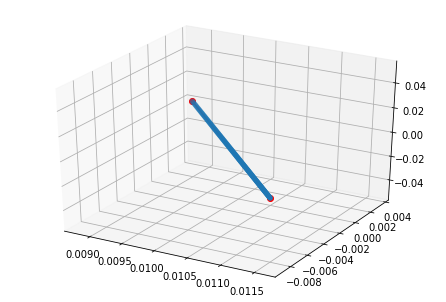

2D grammi poy antiproswpeyei tin epilegmeni stin eikona akmi


In [6]:
p1=np.array([0.0088,0.0035]) 
p2=np.array([0.0116,-0.0089]) 
k,l=find_line_par(p1,p2) 
linepar_im=k,l

# ME TI SEIRA TA STOIXEIA: No.FWTO, X0 , Y0, Z0 , F ,W , K, CAMERA ID
# ORIA    4G0R6615.JPG      1015.862      1018.529    103.851    130.0873  -44.0143   74.5052         

X0=1015.862 
Y0=1018.529
Z0=103.851
O=np.array([[X0,Y0,Z0]])
c=0.0245
b=P.shape[0]
bb=120
R=R_wfk(-44.0143,130.0873,74.5052)
# not sure if this a right thing to do, create pim
#pim__=Upimage(P,c,X0,Y0,Z0,R)



pline_x=np.mgrid[p1[0]:p2[0]:120j]
pline_y=np.zeros(bb)
pline_y=k*pline_x[:] + l


pim=np.zeros((bb,2))
for i in range (bb):
    pim[i,0]=pline_x[i]
    pim[i,1]=pline_y[i]
        
x1,y1=p1.T
x2,y2=p2.T
linex = [x1, x2]
liney = [y1,y2]
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
fig = plt.figure()
ax = Axes3D(fig)
ax.scatter(pim[:,0],pim[:,1])
ax.plot(linex, liney, 'r-o',label='Fit line')
#plt.savefig('fit data in line .png')
plt.show()
print ("2D grammi poy antiproswpeyei tin epilegmeni stin eikona akmi")

In [7]:
linepar_im

(-4.428571428571431, 0.04247142857142859)

In [8]:

print (p1)
print (p2)

[0.0088 0.0035]
[ 0.0116 -0.0089]


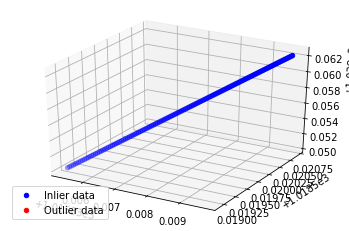

In [9]:
#efarmogi strofis sintetagmenwn pim kata w,f,k (exwterikou pros) kai metathesi sto X0Y0Z0:
# pim_0=[ (X0,Y0,Z0)-(R^-1*pim^-1+)^-1]


__=pim
pim=np.zeros((bb,3))
for i in range(3):
    if i==2:
        pim[:,i]=-c
    else:
        pim[:,i]=__[:,i]
        
        
R_1=np.linalg.inv(R)
pim_1=np.matrix.transpose(pim)
xyzp_1=np.zeros((3,1))
xyzp_1=np.dot(R_1,pim_1)
xyzp_1=(xyzp_1.T)
pim_0=np.array(O+xyzp_1)

_=show_3d_line(pim_0,0.000014)


In [10]:
_=np.max(pim[:,1]) 
e=np.where(pim[:,1]==_)
e=e[0]
p11=np.array([pim[e,0],pim[e,1],pim[e,2]])
p11=np.transpose(p11) 
ea=e[0]


_=np.min(pim[:,1]) 
e=np.where(pim[:,1]==_)
e=e[0]
p22=np.array([pim[e,0],pim[e,1],pim[e,2]])
p22=np.transpose(p22) 
eb=e[0]

p1_0=np.array([pim_0[ea,0],pim_0[ea,1],pim_0[ea,2]])
p2_0=np.array([pim_0[eb,0],pim_0[eb,1],pim_0[eb,2]])
p1_0=np.array([p1_0])
p2_0=np.array([p2_0])

print (p1_0,p2_0)

[[1015.83972518 1018.52067289  103.8621549 ]] [[1015.83531085 1018.51893516  103.85036109]]


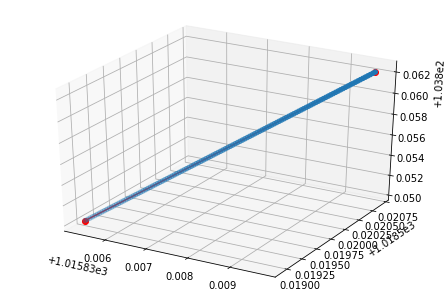

In [11]:
#   eyresi 3D eytheias inliers_pim_0 (metasximatismwnis grammis apo 2D se 3D -metathesi & strofi)
###         p1_0, p2_0, p3_0

data=pim_0



#1st point:
x1=p1_0[0,0]
y1=p1_0[0,1]
z1=p1_0[0,2]
x11=p1_0   


#2nd point:
x2=p2_0[0,0]
y2=p2_0[0,1]
z2=p2_0[0,2]
x22=p2_0


linex = [x1, x2]
liney = [y1,y2]
linez = [z1,z2]

#verifying:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure()
ax = Axes3D(fig)
ax.scatter(data[:,0],data[:,1],data[:,2])
ax.plot(linex, liney, linez, 'r-o',label='Fit line')
#plt.savefig('fit data in line .png')
plt.show()



In [12]:
#  edw shortest distance of every point from designated plane 

abcd=np.zeros((2,4))
k=0
abcd=ABCDk(p1_0,p2_0,X0,Y0,Z0,k,abcd)
#abcd=ABCDk(p11,p22,X0,Y0,Z0,k,abcd)
print (abcd)
thres=0.007
biggest_dist_inl=0
biggest_dist=0
j=0
for i in range (b):
    dist=shortest_distance(P,i,abcd,k)
    if (-thres<=dist) and (dist<=thres):
        j+=1
        if dist>biggest_dist_inl :
            
            biggest_dist_inl=dist
            
    if dist>biggest_dist :
        biggest_dist=dist
Plane=np.zeros((j,3))

j=0
for i in range (b):
    dist=shortest_distance(P,i,abcd,k)
    if (-thres<=dist) and (dist<=thres):
        Plane[j,:]=P[i,:]
        j+=1


print ( biggest_dist_inl, 'is the biggest distance between inliers and plane')
print (biggest_dist, 'is the biggest distance between all data and the plane')
print ('The points that were included in the above restrictions are ', Plane.shape[0])
print ('this kind of noise in the data has to be eliminated indispensably')

debug is
-5.551115123125783e-17
[[ 1.17592567e-04 -3.11946398e-04  1.94911396e-06  1.98066215e-01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]]
0.006983101254383101 is the biggest distance between inliers and plane
6.23336682192295 is the biggest distance between all data and the plane
The points that were included in the above restrictions are  1189
this kind of noise in the data has to be eliminated indispensably


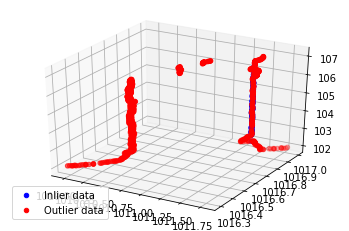

inliers: 294
Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai: 4.573872970064889e-05 0.00020255723153145104
outliers: 895


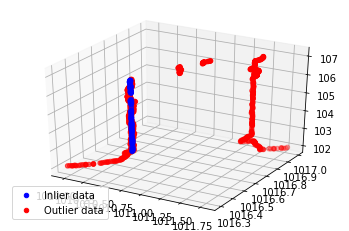

inliers: 142
Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai: 2.958944048721268e-05 0.0001310389507290868
outliers: 753


In [ ]:
loops_Ransac=Plane
check=False
i=0
while check==False :
    # or while check==False or null inliers_Pl (skepsou ksana poy tha mpei to while)
    # pinakes inliers and outliers of each loop
    if i<=1:
#1st loop    
        inliers1,loops_Ransac=model_True(loops_Ransac)
        # outliers are considered the next input of the ransac-loop !
        dist1=dist_point_to_point(inliers1,O)
        i=1
#2nd and all the rest loops:       
    inliers2,loops_Ransac=model_True(loops_Ransac)
    # outliers are considered the next input of the ransac-loop !
    dist2=dist_point_to_point(inliers2,O)
    i+=1
    
    if dist1>dist2 :
        epilogi=inliers2
        # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
        _=File_exportTo_CloudCompare(epilogi)
        check=ask_user()      #epistrefei timi true false
        print (check)
        if check==False:
            epilogi=inliers1
            # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
            _=File_exportTo_CloudCompare(epilogi)
            check=ask_user()  #epistrefei timi true false
    elif dist1<dist2 :
        epilogi=inliers1
        # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
        _=File_exportTo_CloudCompare(epilogi)
        check=ask_user()      #epistrefei timi true false
        if check==False:
            epilogi=inliers2
            # DEIXE TIN  STON XRISTI KAI RWTA TON AN  AYTI  EINAI I SWSTI AKMI. check= True or False gia sinexeia-i mi- tou loop
            _=File_exportTo_CloudCompare(epilogi)
            check=ask_user()   #epistrefei timi true false     
    else:
        while True:
            print ('Choose the edge that was selected on the original photo. Is it A edge, B edge, or C not one of them is the right one? ')
            data = input("Pick an answer from A to C as explained:")
            if data.lower() not in ('a', 'b', 'c'):
                print("Not an appropriate choice.")  # EMFANISE KAI TIS 2 KAI BALE TO XRISTI NA DIALEKSEI
            else:
                break
        if data.lower() in ('a', 'b'):
            check=True
        else:
            check=False
                
    if check==False:
        if dist1>dist2 :
            inliers1=inliers2
            dist1=dist2
            


 9 seconds to run

In [ ]:

if check==True:
    result=FindIf_belongsto_photo(epilogi)
    _=File_exportTo_CloudCompare(result)    
        
            
        


In [ ]:
pwd

In [ ]:


def FindIf_belongsto_photo(result_im):
    # elegxos an i epilegmeni akmi einai i pragmatiki poy anixneytike stin eikona.
    FindIf_belongsto_photo=np.full((result_im.shape[0]), False, dtype=bool)
    for i in range (result_im.shape[0]):
        if ((-0.018<=result_im[i,0] and result_im[i,0]<=0.018) and (-0.012<=result_im[i,1] and result_im[i,1]<=0.012)):
            FindIf_belongsto_photo[i]=True
    j=np.sum(FindIf_belongsto_photo==True)
    result=FindIf_belongsto_photo(j,3)
    j=0
    for i in range (result_im.shape[0]):
        if FindIf_belongsto_photo[i]==True:
            result[j,:]=result_im[i,:]
            j+=1
    return result

def is_model_valid(inl_Pl,linepar_im): 
    #  Run check to results, to prove that the selected line is the real one.
    threshold=12*10**-6
    result=inl_Pl # : is the selected line detected. 
    result_im=Upimage(result,c,X0,Y0,Z0,R)
    res_x,res_y,_=result_im.T
    # edw:  Anixneysi μεσω ελαχιστων τετρaγωνων της καλύτερης ευθειας, y=ax+b eyresi parametrwn a,b.  
    # edw : stin eikona result_im
    line_par1=least_squares(result_im)
    # Bimata gia elegxo Dx, Dy diaforwn sintetagmenwn.
    #1. orismos pinakwn:
    x_ch=np.zeros(result_im.shape[0])
    y_ch=np.zeros(result_im.shape[0])
    Dx=np.zeros(result_im.shape[0])
    Dy=np.zeros(result_im.shape[0])
     #2. Eyresi diaforwn
    for i in range (result_im.shape[0]):
        y_ch[i]=linepar_im[0]*res_x[i]+ linepar_im[1]
        x_ch[i]=(1/linepar_im[0])*res_y[i]-(linepar_im[1]/linepar_im[0])
    for i in range (result_im.shape[0]):
        Dx[i]= abs(res_x[i]- x_ch[i])
        Dy[i]= abs(res_y[i]- y_ch[i])
    print ("Oi megistes diafores sintetagmenwn kata Dx kai Dy antistoixa einai:",Dx.max(), Dy.max())
    if Dx.max()<=thres or Dy.max()<=thres:
        belongsto_selected_line=True
    else:
        belongsto_selected_line=False
  #  Telos elegxou, ara aporipsi i oxi tis epilegmenis akmis.
    return belongsto_selected_line  


def Epilegmeni_akmi_inliers(Plane,inliers_Pl):
    print ("Stin epanalipsi",i,"i epilegmeni akmi exei inliers=",np.sum(inliers_Pl==True))
    j=np.sum(inliers_Pl==True)
    inl_Pl=np.zeros((j,3))
    j=0
    for i in range (inliers_Pl.shape[0]) :
        if inliers_Pl[i]==True:
            # edw dimiourgountai o pinakas telikos twn inliers: i
            inl_Pl[j,:]=Plane[i,:]  #1: tis akmis poy anixneytike sto pim 
            j+=1
    return inl_Pl
            
def epilogi_se_outliers(Plane,inliers_Pl):    
## if check==False:

    print (np.sum(inliers_Pl==False))
    j=np.sum(inliers_Pl==False)
    outliers=np.zeros((j,3))
    j=0
    for i in range (inliers_Pl.shape[0]) :
        if inliers_Pl[i]==False:
            # edw dimiourgountai o pinakas telikos twn newn inliers :
            outliers[j,:]=Plane[i,:]  #1:tis akmis poy anixneytike sto pim 
            j+=1
        return outliers
#########################################################################################            
def dist_point_to_point(inliers,O):
    x1,y1,z1=O.T
    _=inliers.shape[0]
    dist=np.zeros((_,3))
    for i in range (_):
        x2,y2,z2=inliers[i,:].T
        dist[i]=np.sqrt((y2-y1)**2+(x2-x1)**2+(z2-z1)**2)
    min_dist=np.max(dis)    # iparxei logiki gia to giati epilexthike i max anti i min. logw prooptikis tha peftei panta swsta aytos o periorismos enw to min exei lathi ! 
    return min_dist

     
def ask_user():
    _=False
    while _==False:
        User= input("Is the selected edge the one inserted in the program? Answer only with <<y>> for yes and <<n>> for No ")
        User=User.lower()
        if User not in ('y', 'yes', 'n', 'no','nai','oxi'):
            User= input('The value you entered is not valid Try again.Answer only with <<y>> for yes and <<n>> for No. ')
        else:
            _=True  
    if User in ('y', 'yes'):
        User=True #brethike i akmi
    else:
        User=False  # 
        print ('Sinexeia elegxwn,  den brethike akomi i zitoumeni akmi')
        
    return User
        
def File_exportTo_CloudCompare(epilogi):
    result=epilogi
    df = pd.DataFrame(data=result.astype(float))
    df.to_csv('epilegmeni_akmi.csv', sep=' ', header=False, float_format='%.2f', index=False)
    
   # export to cloudcompare 
    filePath = "C:\\Users\\gd\\Desktop\\NAXOS\\Textured_Model\\naosDimitrasNaxosMelina_PointcCloud.obj" #sure thing
    filepath2='C:\\Users\\gd\\Desktop\\DIPLOMATIKI\\python askiseis diplwmatikis\\projects\\project_1_4G0R6724\\outfile_2o.csv' #change please
    subprocess.Popen(['C:\Program Files\CloudCompare\CloudCompare', filePath,filepath2 ])    


In [ ]:
h=np.zeros((4,1))
ABCd=abcd
#o hh pinakas apodeiknuei  oti ta 2 sistimata pim_0 kai P epigeio pleon einai parallila!
h[0,0]=np.array(ABCd[0,0]/ABCd[1,0])
h[1,0]=np.array(ABCd[0,1]/ABCd[1,1])
h[2,0]=np.array(ABCd[0,2]/ABCd[1,2])
h[3,0]=np.array(ABCd[0,3]/ABCd[1,3])